# Predictive Maintenance – Classification mit dem Hybridmodell

**Ziel:** Maschinenfehlschläge vorhersagen und die Kosten **FP + 6 × FN** minimieren. Jeder Alarm führt im Aufgabenszenario zur Expertenprüfung.

Die Gliederung folgt dem achtteiligen Data-Mining-Ablauf aus `classification.ipynb`. Das Notebook verwendet die vorhandenen Funktionen aus `modell.py` und `physik.py`. Für die Prüfung nutzen wir die wiederholte stratifizierte Kreuzvalidierung des Abgabemodells. So bleiben Modell und Ergebnisse mit dem Projektbericht vergleichbar.

**Start:** Notebook im Projektordner öffnen, einen Python-Kernel mit `requirements-notebook.txt` auswählen und die Zellen von oben nach unten ausführen. Gruppenname und Eingabepfade stehen in der ersten Codezelle.

In [1]:
import re
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.figure import Figure
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits

from modell import (
    ECONOMIC_THRESHOLD, FEATURES, SEEDS, TARGET,
    FailureModel, counts, evaluate, forecast, read_data,
)
from physik import physical_inputs

# Suche die bereitgestellten Daten zuerst neben dem Notebook, dann in Downloads.
GRUPPENNAME = "GRUPPENNAME"
PROJEKT = Path.cwd()
MODELLING_DATEI = PROJEKT / "modeling.csv"
CHALLENGE_DATEI = PROJEKT / "challenge.csv"
if not MODELLING_DATEI.is_file():
    MODELLING_DATEI = Path.home() / "Downloads" / "modeling.csv"
if not CHALLENGE_DATEI.is_file():
    CHALLENGE_DATEI = Path.home() / "Downloads" / "challenge.csv"
AUSGABEORDNER = Path("results")

def diagramm_anzeigen(fig):
    # Die Grafik als Bild direkt in der Ausgabezelle anzeigen.
    bild = BytesIO()
    fig.savefig(bild, format="png", dpi=115, bbox_inches="tight")
    display(Image(data=bild.getvalue()))

## 1 · Daten verstehen und prüfen

Jede Zeile repräsentiert einen Produktionsvorgang. Wir prüfen Spalten, Produktvarianten, Sensorwerte und Zielklassen. Die Ausfälle sind selten. Deshalb bewertet die Aufgabe die **Kosten der beiden Fehlerarten**. Extremwerte können für die Ausfallerkennung entscheidend sein und bleiben in der Analyse.

In [2]:
# Das gleiche Eingabeschema wie beim normalen Abgabelauf verwenden.
daten = read_data(MODELLING_DATEI, labeled=True)
X = daten[FEATURES]
y = daten[TARGET].to_numpy(dtype=int)
anzahl = f"{len(daten):,}".replace(",", ".")
print(f"{anzahl} Vorgänge | {int(y.sum())} Ausfälle | {X.duplicated().sum()} doppelte Merkmalszeilen")

klassen = daten[TARGET].value_counts().sort_index()
display(pd.DataFrame({"Anzahl": klassen, "Anteil [%]": 100 * klassen / len(daten)}).round(2))
varianten = daten.groupby("Type")[TARGET].agg(Vorgänge="size", Ausfälle="sum", Ausfallquote="mean")
varianten["Ausfallquote"] = (100 * varianten["Ausfallquote"]).round(2)
display(varianten.rename(columns={"Ausfallquote": "Ausfallquote [%]"}))

8.000 Vorgänge | 271 Ausfälle | 0 doppelte Merkmalszeilen


,Anzahl,Anteil [%]
Machine failure,,
0,7729,96.61
1,271,3.39


,Vorgänge,Ausfälle,Ausfallquote [%]
Type,,,
H,795,18,2.26
L,4808,184,3.83
M,2397,69,2.88


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,8000.00,8000.00,8000.00,8000.00,8000.00
mean,300.00,310.00,1538.33,40.00,107.84
std,1.99,1.48,178.48,9.95,63.65
min,295.30,305.70,1181.00,3.80,0.00
25%,298.30,308.80,1423.00,33.20,53.00
50%,300.10,310.10,1503.00,40.10,108.00
75%,301.50,311.10,1611.00,46.70,162.00
max,304.50,313.80,2886.00,76.60,253.00


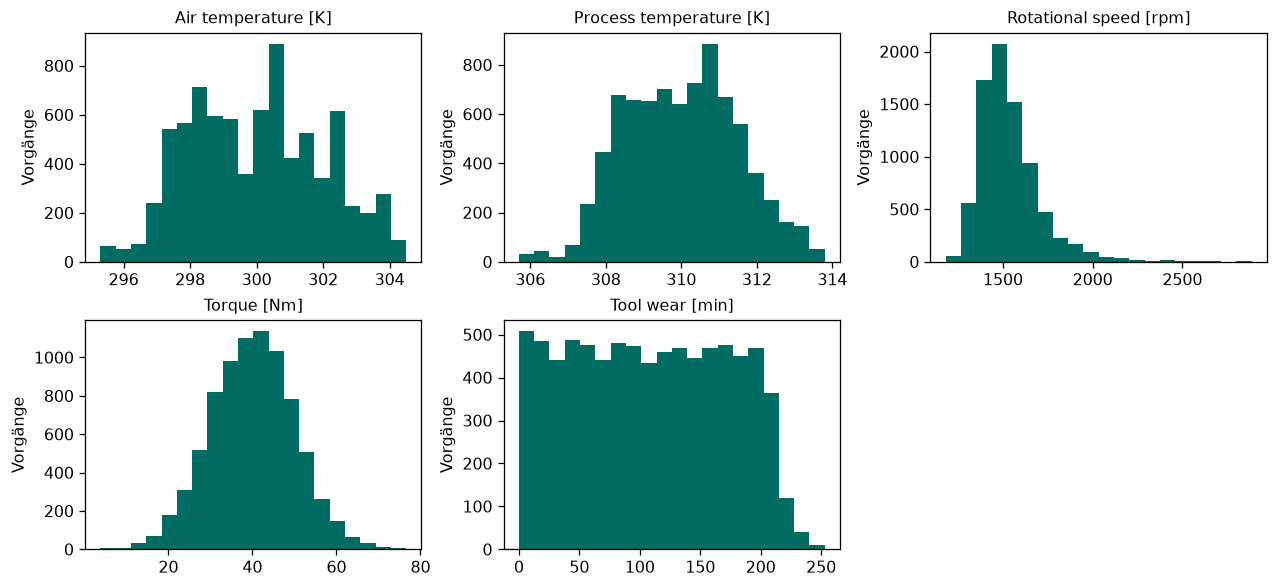

In [3]:
display(daten[FEATURES[1:]].describe().round(2))

# Die Verteilungen zeigen, wie eng oder breit die einzelnen Sensorwerte streuen.
fig = Figure(figsize=(11, 5), layout="constrained")
axes = fig.subplots(2, 3)
for ax, spalte in zip(axes.flat, FEATURES[1:]):
    ax.hist(daten[spalte], bins=20, color="#006C62")
    ax.set_title(spalte, fontsize=10)
    ax.set_ylabel("Vorgänge")
axes.flat[-1].set_visible(False)
diagramm_anzeigen(fig)

## 2 · Daten in Trainings- und Prüffalten trennen

Ein Durchlauf nutzt fünf stratifizierte Falten mit ähnlichen Klassenanteilen. Jeweils vier Falten dienen zum Training und die fünfte zur Prüfung. So erhält jede Zeile pro Durchlauf genau eine Vorhersage aus einer Prüfung, in deren Training sie nicht vorkam. Fünf feste Seeds wiederholen dieses Verfahren mit unterschiedlichen Aufteilungen.

In [4]:
# Eine Aufteilung sichtbar machen. Abschnitt 6 rechnet alle fünf Aufteilungen nach.
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEEDS[0])
beispiel_falten = list(splitter.split(X, y))
display(pd.DataFrame([
    {
        "Falte": nummer,
        "Training": len(train),
        "Prüfung": len(test),
        "Ausfälle in der Prüfung": int(y[test].sum()),
    }
    for nummer, (train, test) in enumerate(beispiel_falten, 1)
]).set_index("Falte"))

,Training,Prüfung,Ausfälle in der Prüfung
Falte,,,
1,6400,1600,54
2,6400,1600,54
3,6400,1600,54
4,6400,1600,54
5,6400,1600,55


## 3 · Merkmale aufbereiten

Der Regelkern berechnet **Temperaturabstand**, **mechanische Leistung** und **Standzeit × Drehmoment** aus den Eingangsspalten. Die Tabelle macht diese Merkmale sichtbar. Das Modell erhält weiterhin die sechs Originalspalten und verwendet intern dieselben Formeln. In der Verschleißstufe geht die Produktvariante als geordnete Stufe L=0, M=1, H=2 ein.

In [5]:
# Dieselbe Merkmalsfunktion wie im Regelkern für eine Vorschau auf die Ableitungen nutzen.
leistung, differenz, drehzahl, verschleisslast, variante = physical_inputs(X)
beispiel_merkmale = pd.DataFrame({
    "Produktvariante": variante,
    "Temperaturabstand [K]": differenz,
    "Mechanische Leistung [W]": leistung,
    "Drehzahl [U/min]": drehzahl,
    "Verschleißlast [min × Nm]": verschleisslast,
}, index=X.index)
display(beispiel_merkmale.head().round(2))

,Produktvariante,Temperaturabstand [K],Mechanische Leistung [W],Drehzahl [U/min],Verschleißlast [min × Nm]
0,L,10.8,5243.23,1763.0,1533.6
1,L,8.9,6811.44,1545.0,2862.8
2,H,9.4,6714.87,1397.0,9639.0
3,L,10.9,6508.65,1366.0,500.5
4,M,8.8,5930.99,1609.0,140.8


## 4 · Kostenfunktion und wenige Modellvarianten

Ein Fehlalarm (**FP**) kostet eine Einheit. Ein übersehener Ausfall (**FN**) kostet sechs. Wir vergleichen den Hybrid mit dem reinen Regelkern und zwei Varianten, die den Beitrag zentraler Modellentscheidungen prüfen. Die Referenz „Nie Alarm“ zeigt die Kosten durchgehender Freigabe.

In [6]:
# Ein Fehlalarm und ein übersehener Ausfall ergeben zusammen sieben Einheiten.
assert counts(np.array([0, 1]), np.array([1, 0]))["cost"] == 7
modelle = {
    "Hybridmodell": FailureModel,
    "Physikalische Regeln": lambda: FailureModel(wear_alarm=False),
    "Regeln mit gerundetem Temperaturabstand": lambda: FailureModel(wear_alarm=False, round_gap=True),
    "Regeln mit getrennten Belastungsgrenzen": lambda: FailureModel(wear_alarm=False, pool_stress=False),
}

## 5 · Modell und Alarmschwelle auswählen

Für dieses Notebook steht die bereits im Projekt gewählte Konfiguration fest. Das **Hybridmodell** prüft zuerst die physikalischen Regeln. Für die übrigen Vorgänge schätzt es das Ausfallrisiko mit einer regularisierten logistischen Regression (`C=1`). Die Alarmschwelle der Verschleißstufe ist **1/7**. Bei geschätztem Risiko \(p\) kostet Freigeben im Erwartungswert \(6p\), ein Alarm \(1-p\).

Die folgende Prüfung rechnet die Ergebnisse dieser Konfiguration nach. Die historisch getesteten Varianten und die innere Abstimmung zusätzlicher Schwellen stehen in den Versuchsprotokollen des Projekts. Sämtliche Versuche verwenden dieselbe beschriftete Kohorte. Die Wiederholungen messen die Stabilität über Aufteilungen.

In [7]:
# Auswahl und Schwelle stehen vor der Auswertung fest.
GEWAEHLTES_MODELL = "Hybridmodell"
modell_factory = modelle[GEWAEHLTES_MODELL]
print(f"{GEWAEHLTES_MODELL} | Schwelle der Verschleißstufe: {ECONOMIC_THRESHOLD:.2%}")

Hybridmodell | Schwelle der Verschleißstufe: 14.29%


## 6 · Auf den Prüffalten bewerten

Jede Variante lernt ihre Regeln und gegebenenfalls die Verschleißstufe in der jeweiligen Trainingsfalte neu. Die Tabelle zeigt mittlere Kosten, Fehlalarme und übersehene Ausfälle pro vollständigem Durchlauf. Die Konfusionsmatrix zeigt den ersten Durchlauf mit Seed 2006.

In [8]:
# Die kanonische Auswertung trainiert für jede Falte ein frisches Modell.
with threadpool_limits(limits=1):
    validierung = {name: evaluate(daten, factory) for name, factory in modelle.items()}

referenz = counts(y, np.zeros_like(y))
vergleich = pd.DataFrame([
    {
        "Modell": name,
        "Kosten Ø": np.mean([lauf["cost"] for lauf in laeufe]),
        "Fehlalarme Ø": np.mean([lauf["fp"] for lauf in laeufe]),
        "Übersehene Ausfälle Ø": np.mean([lauf["fn"] for lauf in laeufe]),
    }
    for name, laeufe in {**validierung, "Nie Alarm": [referenz]}.items()
]).set_index("Modell").sort_values("Kosten Ø")
display(vergleich.round(1))

,Kosten Ø,Fehlalarme Ø,Übersehene Ausfälle Ø
Modell,,,
Hybridmodell,237.6,25.2,35.4
Physikalische Regeln,252.0,0.0,42.0
Regeln mit getrennten Belastungsgrenzen,258.8,0.8,43.0
Regeln mit gerundetem Temperaturabstand,300.0,0.0,50.0
Nie Alarm,1626.0,0.0,271.0


Seed 2006: 240 Kosteneinheiten | Recall 86.7%


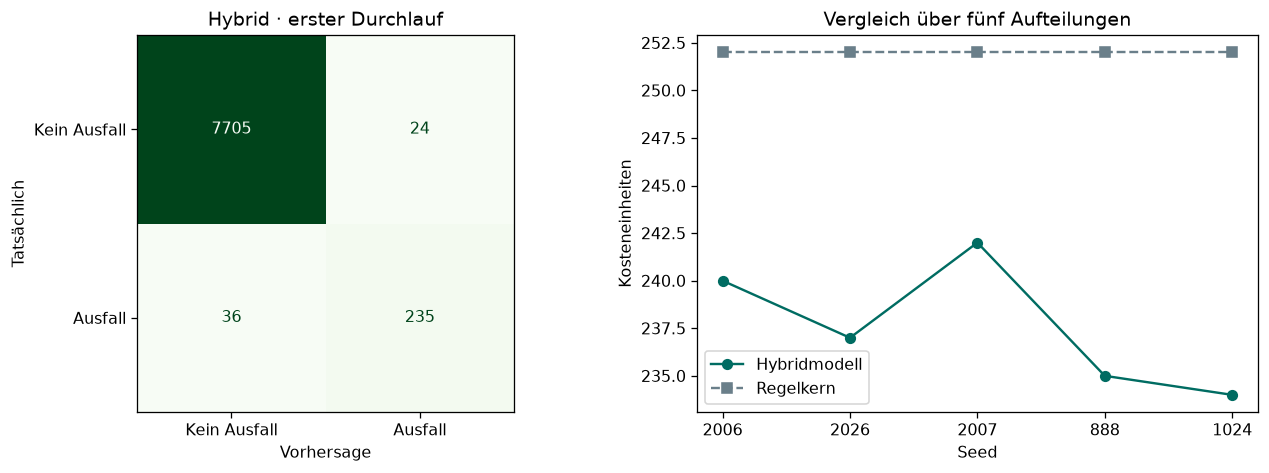

In [9]:
hybrid_cv = validierung[GEWAEHLTES_MODELL]
regel_cv = validierung["Physikalische Regeln"]
erster_lauf = hybrid_cv[0]
matrix = np.array([
    [erster_lauf["tn"], erster_lauf["fp"]],
    [erster_lauf["fn"], erster_lauf["tp"]],
])
recall = erster_lauf["tp"] / (erster_lauf["tp"] + erster_lauf["fn"])
print(f"Seed {erster_lauf['seed']}: {erster_lauf['cost']} Kosteneinheiten | Recall {recall:.1%}")

# Links die Fehlertypen, rechts die Kostenstabilität auf denselben Seeds.
fig = Figure(figsize=(11, 4), layout="constrained")
axes = fig.subplots(1, 2)
ConfusionMatrixDisplay(matrix, display_labels=["Kein Ausfall", "Ausfall"]).plot(
    ax=axes[0], colorbar=False, cmap="Greens", values_format="d"
)
axes[0].set(xlabel="Vorhersage", ylabel="Tatsächlich", title="Hybrid · erster Durchlauf")
labels = [str(seed) for seed in SEEDS]
axes[1].plot(labels, [lauf["cost"] for lauf in hybrid_cv], "o-", color="#006C62", label="Hybridmodell")
axes[1].plot(labels, [lauf["cost"] for lauf in regel_cv], "s--", color="#6A7F8A", label="Regelkern")
axes[1].set(xlabel="Seed", ylabel="Kosteneinheiten", title="Vergleich über fünf Aufteilungen")
axes[1].legend()
diagramm_anzeigen(fig)

## 7 · Zusammenhänge verstehen

Ein Alarm entsteht durch mindestens eine physikalische Regel oder durch den Verschleißscore. Zur Interpretation zeigen wir die **tatsächlich gelernten Grenzen** eines Beispielmodells und die Anzahl der Alarme je Regel auf seiner Prüffalte. Mehrere physikalische Regeln können beim selben Vorgang auslösen. Die Verschleißstufe ergänzt Alarme bei Vorgängen, die der Regelkern freigibt.

In [10]:
# Für das Beispiel nur die erste Trainingsfalte des ersten Seeds verwenden.
train, test = beispiel_falten[0]
beispielmodell = modell_factory().fit(X.iloc[train], y[train])
grenzen = beispielmodell.thresholds_
zeilen = [
    ("Leistung unter", grenzen["power_low"], "W"),
    ("Leistung über", grenzen["power_high"], "W"),
    ("Kühlung: Temperaturabstand unter", grenzen["gap"], "K"),
    ("Kühlung: zugleich Drehzahl unter", grenzen["speed"], "U/min"),
    *[(f"Belastung über, Typ {typ}", grenze, "min × Nm") for typ, grenze in grenzen["stress"].items()],
]
if beispielmodell.residual_ is not None:
    zeilen.extend([
        ("Beginn des Verschleißeffekts", grenzen["wear_hinge"], "min"),
        ("Verschleißalarm ab", 100 * grenzen["wear_probability"], "%"),
    ])
display(pd.DataFrame(zeilen, columns=["Bedingung", "Gelernte Grenze oder Schwelle", "Einheit"]).round(2))

regeln = beispielmodell.rules(X.iloc[test])
display(pd.DataFrame({
    "Alarme": {name: int(flag.sum()) for name, flag in regeln.items()},
    "Davon tatsächliche Ausfälle": {name: int(y[test][flag].sum()) for name, flag in regeln.items()},
}).rename(index={
    "power_low": "Leistung zu niedrig", "power_high": "Leistung zu hoch",
    "heat": "Kühlungsregel", "stress": "Belastungsregel", "wear": "Zusätzlicher Verschleißalarm",
}))

,Bedingung,Gelernte Grenze oder Schwelle,Einheit
0,Leistung unter,3500.00,W
1,Leistung über,9000.00,W
2,Kühlung: Temperaturabstand unter,8.60,K
3,Kühlung: zugleich Drehzahl unter,1380.00,U/min
4,"Belastung über, Typ L",11000.00,min × Nm
5,"Belastung über, Typ M",12000.00,min × Nm
6,"Belastung über, Typ H",13000.00,min × Nm
7,Beginn des Verschleißeffekts,200.00,min
8,Verschleißalarm ab,14.29,%


,Alarme,Davon tatsächliche Ausfälle
Leistung zu niedrig,8,8
Leistung zu hoch,9,9
Kühlungsregel,17,17
Belastungsregel,13,13
Zusätzlicher Verschleißalarm,3,1


## 8 · Challenge vorhersagen und Kosten schätzen

Jetzt lernt das festgelegte Modell aus allen beschrifteten Zeilen. Anschließend lesen wir `challenge.csv` ein und schreiben die Vorhersagen in Originalreihenfolge. Die erwarteten Kosten und der Prognosebereich werden aus den bisherigen Prüffalten auf die Zahl der neuen Vorgänge hochgerechnet. Die Schätzung setzt vergleichbare, annähernd unabhängige Vorgänge voraus.

In [11]:
if not re.fullmatch(r"[\w -]+", GRUPPENNAME) or not GRUPPENNAME.strip():
    raise ValueError("GRUPPENNAME darf Buchstaben, Ziffern, Leerzeichen, _ und - enthalten.")

# Nach der Modellwahl auf allen beschrifteten Daten trainieren und erst dann die Challenge lesen.
finales_modell = modell_factory().fit(X, y)
challenge = read_data(CHALLENGE_DATEI)
vorhersagen = finales_modell.predict(challenge)
AUSGABEORDNER.mkdir(parents=True, exist_ok=True)
ausgabedatei = AUSGABEORDNER / f"challenge_prediction_{GRUPPENNAME}.csv"
pd.DataFrame({TARGET: vorhersagen}).to_csv(ausgabedatei, index=False, lineterminator="\n")

# Die Datei erneut lesen und Spaltenschema sowie Zeilenfolge prüfen.
kontroll_csv = pd.read_csv(ausgabedatei)
assert list(kontroll_csv.columns) == [TARGET]
assert np.array_equal(kontroll_csv[TARGET].to_numpy(), vorhersagen)
print(f"CSV: {ausgabedatei} | {len(vorhersagen)} Vorhersagen | {vorhersagen.sum()} Alarme")

schaetzung = forecast(hybrid_cv, len(y), len(challenge))
untergrenze, obergrenze = schaetzung["predictive_95"]
print(f"Erwartete Kosten: {schaetzung['expected_cost']:.1f}")
print(f"Geschätzter 95-%-Prognosebereich: {untergrenze}–{obergrenze}")

CSV: results\challenge_prediction_GRUPPENNAME.csv | 2000 Vorhersagen | 63 Alarme
Erwartete Kosten: 59.4
Geschätzter 95-%-Prognosebereich: 25–104


**Grundlage:** Aufgabenstellung *Gruppenarbeit Classification*, TH Mannheim, und die Methoden-/Ergebnisdokumentation des Projekts. Gliederung nach dem im Team bereitgestellten `classification.ipynb`. KI-unterstützter Notebook-Entwurf mit OpenAI Codex (16.11.2026).